# 03 – Projection (προβολή στον πληθυσμό) και αβεβαιότητα

Με τα βάρη του notebook 02 απαντάμε στο επιχειρηματικό ερώτημα:
**Πώς αλλάζουν τα KPIs των τμημάτων (penetration, μερίδιο πωλήσεων, δαπάνη ανά νοικοκυριό) μετά τη στάθμιση, και πόσα θα ξόδευαν όλα τα νοικοκυριά των ΗΠΑ σε ένα χρόνο;**

Τρία σενάρια:
- **Unweighted:** τα 730 νοικοκυριά με δημογραφικά, όπως είναι.
- **Rake only:** στάθμιση μόνο στα δημογραφικά.
- **NR + rake (final):** διόρθωση non-response + raking + trimming.

Στο τέλος υπολογίζουμε **95% διαστήματα εμπιστοσύνης με bootstrap**, ξανακάνοντας όλη τη στάθμιση σε κάθε επανάληψη.

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.chdir(r'C:\Projects\circana-panel-weighting')
CLEAN, IMG, TARGETS = 'data-clean', 'images', 'data-targets'
pd.set_option('display.width', 160)

hh = pd.read_csv(f'{CLEAN}/households.csv')
weights = pd.read_csv(f'{CLEAN}/weights.csv')

with sqlite3.connect(f'{CLEAN}/panel.db') as con:
    dept_long = pd.read_sql('''
        SELECT household_key, department, SUM(sales_value) AS spend
        FROM transactions
        GROUP BY household_key, department
    ''', con)

dept = dept_long.pivot(index='household_key', columns='department', values='spend').fillna(0)
print('Households x departments:', dept.shape)

Households x departments: (2479, 37)


## 1. Πίνακας ανάλυσης
Ένα νοικοκυριό ανά γραμμή: βάρη + δαπάνη ανά τμήμα. Κρατάμε τα 10 μεγαλύτερα τμήματα (με βάση τις αστάθμιστες πωλήσεις).

In [2]:
resp = weights.merge(hh[['household_key', 'annual_spend']], on='household_key')
resp = resp.merge(dept, left_on='household_key', right_index=True, how='left').fillna(0)

TOP = dept.loc[resp['household_key']].sum().sort_values(ascending=False).head(10).index.tolist()
POP = resp['w_final'].sum()
print('Households:', len(resp), '| Population (sum of final weights):', f'{POP:,.0f}')
print('Top departments:', TOP)
print('Check: annual spend = sum of departments ->',
      np.allclose(resp['annual_spend'], resp[dept.columns].sum(axis=1)))

Households: 730 | Population (sum of final weights): 115,969,540
Top departments: ['GROCERY', 'DRUG GM', 'KIOSK-GAS', 'PRODUCE', 'MEAT', 'MEAT-PCKGD', 'DELI', 'MISC SALES TRAN', 'PASTRY', 'NUTRITION']
Check: annual spend = sum of departments -> True


## 2. KPIs ανά τμήμα σε κάθε σενάριο
- **Penetration %** = σταθμισμένο % νοικοκυριών που αγόρασαν από το τμήμα.
- **Share of sales %** = μερίδιο του τμήματος στη συνολική δαπάνη.
- **Spend per household** = μέση ετήσια δαπάνη σε όλα τα νοικοκυριά (και σε όσα δεν αγόρασαν).

In [3]:
SCEN = {'unweighted': None, 'rake_only': 'w_rake_only', 'final': 'w_final'}

def kpis(df, wcol):
    w = np.ones(len(df)) if wcol is None else df[wcol].to_numpy()
    total = (df[dept.columns].to_numpy() * w[:, None]).sum()
    out = {}
    for d in TOP:
        x = df[d].to_numpy()
        out[d] = {'penetration_pct': (w * (x > 0)).sum() / w.sum() * 100,
                  'share_pct': (w * x).sum() / total * 100,
                  'spend_per_hh': (w * x).sum() / w.sum()}
    return pd.DataFrame(out).T

res = {name: kpis(resp, col) for name, col in SCEN.items()}
table = pd.concat(res, axis=1).round(1)
table.columns = [f'{a}|{b}' for a, b in table.columns]
table['share_diff_pp'] = (table['final|share_pct'] - table['unweighted|share_pct']).round(1)
table['pen_diff_pp'] = (table['final|penetration_pct'] - table['unweighted|penetration_pct']).round(1)
table[['unweighted|penetration_pct', 'final|penetration_pct', 'pen_diff_pp',
       'unweighted|share_pct', 'rake_only|share_pct', 'final|share_pct', 'share_diff_pp',
       'unweighted|spend_per_hh', 'final|spend_per_hh']]

,unweighted|penetration_pct,final|penetration_pct,pen_diff_pp,unweighted|share_pct,rake_only|share_pct,final|share_pct,share_diff_pp,unweighted|spend_per_hh,final|spend_per_hh
GROCERY,100.0,100.0,0.0,49.9,49.6,49.9,0.0,1714.8,1478.9
DRUG GM,100.0,100.0,0.0,12.9,12.4,12.2,-0.7,441.8,362.6
KIOSK-GAS,62.9,56.4,-6.5,8.1,8.0,7.8,-0.3,279.6,231.6
PRODUCE,100.0,100.0,0.0,7.4,7.8,7.8,0.4,252.6,230.9
MEAT,97.4,96.4,-1.0,6.4,6.5,6.6,0.2,219.0,195.9
MEAT-PCKGD,98.5,97.7,-0.8,4.5,4.6,4.6,0.1,155.0,137.4
DELI,94.0,91.3,-2.7,3.3,3.2,3.3,0.0,112.8,96.7
MISC SALES TRAN,61.9,58.0,-3.9,1.7,1.9,1.9,0.2,58.5,55.6
PASTRY,97.0,96.8,-0.2,1.4,1.5,1.6,0.2,49.0,46.3
NUTRITION,75.5,70.2,-5.3,1.4,1.3,1.3,-0.1,48.0,40.0


## 3. Μέση ετήσια δαπάνη ανά νοικοκυριό
Πόσο αλλάζει το βασικό KPI σε κάθε βήμα της στάθμισης. Για σύγκριση, η πραγματική μέση δαπάνη όλου του static panel (1.406 νοικοκυριά) είναι το «σημείο αναφοράς» για τη διόρθωση non-response (όχι για τα δημογραφικά).

In [4]:
static_mean = hh.loc[hh['static'], 'annual_spend'].mean()
means = pd.DataFrame({
    'scenario': ['All static panel (1,406, reference)', 'Unweighted respondents', 'NR only',
                 'Rake only', 'NR + rake (final)'],
    'mean_annual_spend': [static_mean,
                          resp['annual_spend'].mean(),
                          np.average(resp['annual_spend'], weights=resp['nr_factor']),
                          np.average(resp['annual_spend'], weights=resp['w_rake_only']),
                          np.average(resp['annual_spend'], weights=resp['w_final'])]})
means['mean_annual_spend'] = means['mean_annual_spend'].round(0)
means

,scenario,mean_annual_spend
0,"All static panel (1,406, reference)",2800.0
1,Unweighted respondents,3436.0
2,NR only,2835.0
3,Rake only,3404.0
4,NR + rake (final),2966.0


## 4. Προβολή στον πληθυσμό (projection)
Τα τελικά βάρη αθροίζουν στα **115,97 εκ. νοικοκυριά** των ΗΠΑ. Άρα **Σ(βάρος × δαπάνη)** = εκτιμώμενη ετήσια δαπάνη όλων των νοικοκυριών, **αν** όλα ψώνιζαν με τον τρόπο που ψωνίζουν οι πελάτες αυτής της αλυσίδας.
Είναι υπόθεση και όχι πραγματικό μέγεθος αγοράς: τη γράφουμε στα limitations. Η μέθοδος όμως είναι ίδια με την προβολή ενός panel.

In [5]:
proj = pd.DataFrame({
    'projected_spend_bn': [(resp['w_final'] * resp[d]).sum() / 1e9 for d in TOP],
    'projected_buyers_mn': [(resp['w_final'] * (resp[d] > 0)).sum() / 1e6 for d in TOP]}, index=TOP)
proj.loc['TOTAL (all departments)'] = [(resp['w_final'] * resp['annual_spend']).sum() / 1e9, POP / 1e6]
proj.round(1)

,projected_spend_bn,projected_buyers_mn
GROCERY,171.5,116.0
DRUG GM,42.1,116.0
KIOSK-GAS,26.9,65.4
PRODUCE,26.8,116.0
MEAT,22.7,111.7
MEAT-PCKGD,15.9,113.3
DELI,11.2,105.8
MISC SALES TRAN,6.4,67.2
PASTRY,5.4,112.3
NUTRITION,4.6,81.4


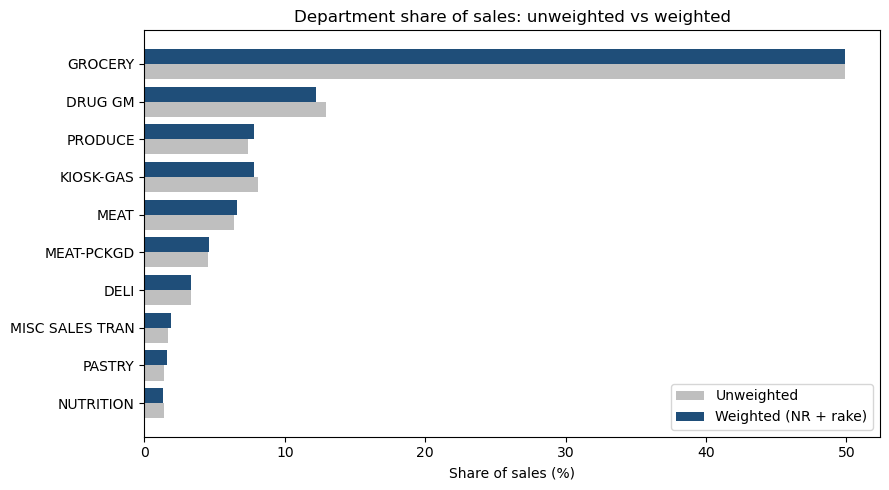

In [6]:
plot = table[['unweighted|share_pct', 'final|share_pct']].sort_values('final|share_pct')
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(plot))
ax.barh(y - 0.2, plot['unweighted|share_pct'], 0.4, label='Unweighted', color='#bfbfbf')
ax.barh(y + 0.2, plot['final|share_pct'], 0.4, label='Weighted (NR + rake)', color='#1f4e79')
ax.set_yticks(y); ax.set_yticklabels(plot.index)
ax.set_xlabel('Share of sales (%)'); ax.set_title('Department share of sales: unweighted vs weighted')
ax.legend(); plt.tight_layout(); plt.savefig(f'{IMG}/department_share_weighted.png', dpi=120); plt.show()

## 5. Bootstrap: πόσο σίγουροι είμαστε;
Σε κάθε μία από τις `B` επαναλήψεις:
1. Παίρνουμε τυχαίο δείγμα **με επανάθεση** από τα 1.406 static νοικοκυριά (ίδιο μέγεθος).
2. Ξανακάνουμε **όλη** τη στάθμιση: non-response factors, raking, trimming.
3. Υπολογίζουμε τα KPIs.

Το 95% διάστημα είναι το 2,5ο και το 97,5ο εκατοστημόριο των αποτελεσμάτων (percentile method). Το συγκρίνουμε με το ίδιο διάστημα χωρίς στάθμιση: η διαφορά δείχνει το «κόστος» της στάθμισης σε ακρίβεια.
Θέλει 1–3 λεπτά.

In [7]:
targets = pd.read_csv(f'{TARGETS}/us_household_targets_acs2012.csv')
high = ['100-124K', '125-149K', '150-199K', '200K+']
targets.loc[(targets['variable'] == 'income') & targets['category'].isin(high), 'category'] = '100K+'
targets = targets.groupby(['variable', 'category'], as_index=False)['households'].sum()
targets['variable'] = targets['variable'].replace({'income': 'income_w'})
RAKE_VARS, LOW, HIGH = ['age', 'income_w', 'hh_size'], 0.25, 5.0

def rake(df, w, max_iter=100, tol=1e-6):
    w = w / w.sum() * POP
    for _ in range(max_iter):
        max_diff = 0
        for var in RAKE_VARS:
            t = targets[targets['variable'] == var].set_index('category')['households']
            current = w.groupby(df[var]).sum()
            w = w * (t / current).reindex(df[var]).to_numpy()
            max_diff = max(max_diff, (abs(current - t) / t).max())
        if max_diff < tol:
            break
    return w

def full_weighting(st):
    nr = st.groupby('spend_quintile')['has_demo'].agg(['size', 'sum'])
    r = st[st['has_demo']].reset_index(drop=True)
    w = rake(r, r['spend_quintile'].map(nr['size'] / nr['sum']).astype(float))
    for _ in range(20):
        rel = w / w.mean()
        if rel.min() >= LOW * 0.95 and rel.max() <= HIGH * 1.05:
            break
        w = rake(r, rel.clip(LOW, HIGH) * w.mean())
    return r, w.to_numpy()

base = hh[hh['static']].copy()
base['spend_quintile'] = pd.qcut(base['annual_spend'], 5, labels=False) + 1
base['income_w'] = base['income'].replace({k: '100K+' for k in high})
base['hh_size'] = base['hh_size'].astype(str).str.replace('.0', '', regex=False)
base = base.merge(dept, left_on='household_key', right_index=True, how='left').fillna(0)

def stats_for(r, w):
    total = (r[dept.columns].to_numpy() * w[:, None]).sum()
    out = {'mean_annual_spend': np.average(r['annual_spend'], weights=w)}
    for d in ['GROCERY', 'DRUG GM', 'KIOSK-GAS', 'PRODUCE']:
        if d in r.columns:
            out[f'{d} share %'] = (w * r[d]).sum() / total * 100
            out[f'{d} penetration %'] = (w * (r[d] > 0)).sum() / w.sum() * 100
    return out

B = 300
rng = np.random.default_rng(42)
boot_w, boot_u = [], []
for b in range(B):
    sample = base.sample(len(base), replace=True, random_state=rng.integers(1e9)).reset_index(drop=True)
    r, w = full_weighting(sample)
    boot_w.append(stats_for(r, w))
    boot_u.append(stats_for(r, np.ones(len(r))))

r0, w0 = full_weighting(base.reset_index(drop=True))
point_w, point_u = stats_for(r0, w0), stats_for(r0, np.ones(len(r0)))
bw, bu = pd.DataFrame(boot_w), pd.DataFrame(boot_u)
ci = pd.DataFrame({'unweighted': pd.Series(point_u),
                   'unw_ci_low': bu.quantile(0.025), 'unw_ci_high': bu.quantile(0.975),
                   'weighted': pd.Series(point_w),
                   'w_ci_low': bw.quantile(0.025), 'w_ci_high': bw.quantile(0.975)})
ci['width_ratio'] = (ci['w_ci_high'] - ci['w_ci_low']) / (ci['unw_ci_high'] - ci['unw_ci_low'])
ci.round(2)

,unweighted,unw_ci_low,unw_ci_high,weighted,w_ci_low,w_ci_high,width_ratio
mean_annual_spend,3435.69,3271.57,3606.44,2966.34,2837.46,3203.16,1.09
GROCERY share %,49.91,49.07,50.70,49.86,48.73,50.74,1.24
GROCERY penetration %,100.00,100.00,100.00,100.00,100.00,100.00,NaN
DRUG GM share %,12.86,12.26,13.44,12.23,11.50,13.00,1.27
DRUG GM penetration %,100.00,100.00,100.00,100.00,100.00,100.00,NaN
KIOSK-GAS share %,8.14,7.45,8.84,7.81,6.71,8.74,1.47
KIOSK-GAS penetration %,62.88,59.46,66.15,56.36,51.40,61.92,1.57
PRODUCE share %,7.35,7.02,7.75,7.78,7.34,8.33,1.33
PRODUCE penetration %,100.00,100.00,100.00,100.00,100.00,100.00,NaN


## 6. Αποθήκευση αποτελεσμάτων σε Excel
Ένα αρχείο `projection_results.xlsx` με φύλλα για τα KPIs των τμημάτων, τις μέσες δαπάνες, την προβολή και τα διαστήματα εμπιστοσύνης, για όποιον δεν χρησιμοποιεί Python.

In [8]:
with pd.ExcelWriter(f'{CLEAN}/projection_results.xlsx') as xl:
    table.to_excel(xl, sheet_name='department_kpis')
    means.to_excel(xl, sheet_name='mean_spend', index=False)
    proj.round(2).to_excel(xl, sheet_name='projection')
    ci.round(2).to_excel(xl, sheet_name='bootstrap_ci')
print('Saved data-clean/projection_results.xlsx')

Saved data-clean/projection_results.xlsx
